# Input drift monitoring: PSI between training and test years

Has the input data moved since the model was trained? This notebook compares each input of the deployed
**15 March SVR** between the training years (**1964–2014**) and the test years (**2015–2025**).

**Population Stability Index (PSI)** for one feature:

1. Cut the training values into 10 bins at their deciles (open-ended end bins, so test values outside the training
   range still count). Features with 10 or fewer distinct values are compared value by value. Missing values get
   their own bin.
2. p = share of training records in each bin, q = share of test records (floored at 10⁻⁶ and renormalised).
3. PSI = Σ (q − p) · ln(q / p), which equals KL(test‖train) + KL(train‖test).

Rule of thumb: **< 0.10 stable, 0.10–0.25 moderate shift, ≥ 0.25 large shift.**

| | |
|---|---|
| Features | the 28 inputs of the deployed SVR (`app/model/svr_mar15_meta.json`) |
| Records | small sample (48 stations with a 2025 record): 2,444 training and 528 test station-years |
| Output | `results/monitoring/` |
| Runtime | a few seconds |

Result (Section 9.6 of the report): 11 of the 28 features shifted strongly; the top eight are all 1–14 March
temperature measures (PSI 0.43–0.59). Mean temperature over 1–14 March rose from 5.95 °C to 8.05 °C (+2.1 °C).

Note: the PSI uses the 48-station small sample so that both periods cover the same stations; the deployed SVR itself
was trained on all 82 stations.

## 1. Data, features and the PSI function

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# Settings
# ============================================================

N_BINS = 10
EPSILON = 1e-6  # small value so that no bin has probability zero

BAR_FIGSIZE = (10, 11)
DIST_FIGSIZE = (12, 4.5)
DPI = 300

# Find the repository root from the notebook's folder
ROOT = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / 'data/model/model_features_mar15.csv').exists()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        'Open this notebook inside the sakura_analytics repository.'
    )

MONITOR_OUT = ROOT / 'results/monitoring'
MONITOR_OUT.mkdir(parents=True, exist_ok=True)

# ============================================================
# Load data
# ============================================================

mar15_monitor = pd.read_csv(
    ROOT / 'data/model/model_features_mar15.csv',
    dtype={'station_id': str},
)

mar1_station_ids = pd.read_csv(
    ROOT / 'data/model/model_features_mar1.csv',
    usecols=['station_id', 'bloom_year'],
    dtype={'station_id': str},
)

small_ids_monitor = set(
    mar1_station_ids.loc[
        mar1_station_ids['bloom_year'] == 2025,
        'station_id',
    ]
)

monitor_data = mar15_monitor.loc[
    mar15_monitor['station_id'].isin(small_ids_monitor)
].copy()

# The 28 features of the deployed 15 March SVR, read from its metadata
SVR_META = ROOT / 'app/model/svr_mar15_meta.json'
monitor_features = json.loads(SVR_META.read_text(encoding='utf-8'))['features']

missing = [
    feature for feature in monitor_features
    if feature not in monitor_data.columns
]

if missing:
    raise ValueError(f'Features missing from the data: {missing}')

print('Monitoring features:', len(monitor_features))

monitor_data[monitor_features] = (
    monitor_data[monitor_features]
    .apply(pd.to_numeric, errors='raise')
)

if np.isinf(
    monitor_data[monitor_features].to_numpy(dtype=float)
).any():
    raise ValueError('Infinite values in the features.')

train_monitor = monitor_data.loc[
    monitor_data['bloom_year'].between(1964, 2014)
].copy()

test_monitor = monitor_data.loc[
    monitor_data['bloom_year'].between(2015, 2025)
].copy()

if train_monitor.empty or test_monitor.empty:
    raise ValueError('Train or Test period is empty.')

if monitor_data.duplicated(['station_id', 'bloom_year']).any():
    raise ValueError('Duplicate station-year rows.')

display(pd.DataFrame([
    {
        'period': name,
        'start_year': frame['bloom_year'].min(),
        'end_year': frame['bloom_year'].max(),
        'records': len(frame),
        'stations': frame['station_id'].nunique(),
    }
    for name, frame in [
        ('Train', train_monitor),
        ('Test', test_monitor),
    ]
]))


# ============================================================
# Shared bins (defined on the training years)
# ============================================================

def make_distribution_table(train_series, test_series):
    observed_train = train_series.dropna()

    if observed_train.empty:
        raise ValueError(
            f'{train_series.name}: all training values are missing.'
        )

    unique_values = np.sort(observed_train.unique())

    # Features with few distinct values: compare value by value
    # (constant columns are handled here too)
    if len(unique_values) <= N_BINS:
        value_to_label = {
            value: f'value={value:g}'
            for value in unique_values
        }

        labels = [
            value_to_label[value] for value in unique_values
        ] + ['Unseen value', 'Missing']

        def categorize(series):
            result = series.map(value_to_label)
            result = result.fillna('Unseen value')
            return result.where(series.notna(), 'Missing')

        train_labels = categorize(train_series)
        test_labels = categorize(test_series)

    else:
        # Inner bin edges = deciles of the training values
        cuts = np.quantile(
            observed_train,
            np.linspace(0, 1, N_BINS + 1)[1:-1],
        )
        cuts = np.unique(cuts)

        # Values outside the training range fall into the end bins
        edges = np.r_[-np.inf, cuts, np.inf]

        labels = [
            f'({edges[i]:.6g}, {edges[i + 1]:.6g}]'
            for i in range(len(edges) - 1)
        ]

        def categorize(series):
            return (
                pd.cut(
                    series,
                    bins=edges,
                    labels=labels,
                    include_lowest=True,
                )
                .astype(object)
                .where(series.notna(), 'Missing')
            )

        train_labels = categorize(train_series)
        test_labels = categorize(test_series)
        labels = labels + ['Missing']

    train_counts = (
        train_labels.value_counts()
        .reindex(labels, fill_value=0)
    )
    test_counts = (
        test_labels.value_counts()
        .reindex(labels, fill_value=0)
    )

    # Drop bins that are empty in both periods
    keep = (train_counts + test_counts) > 0
    train_counts = train_counts.loc[keep]
    test_counts = test_counts.loc[keep]

    p_raw = train_counts.to_numpy(dtype=float) / len(train_series)
    q_raw = test_counts.to_numpy(dtype=float) / len(test_series)

    # Floor at EPSILON, then renormalise to sum to 1
    p = np.maximum(p_raw, EPSILON)
    q = np.maximum(q_raw, EPSILON)
    p = p / p.sum()
    q = q / q.sum()

    log_ratio = np.log(q / p)

    return pd.DataFrame({
        'bin': train_counts.index,
        'train_count': train_counts.to_numpy(),
        'test_count': test_counts.to_numpy(),
        'train_share': p_raw,
        'test_share': q_raw,
        'PSI_contribution': (q - p) * log_ratio,
        'KL_test_train_contribution': q * log_ratio,
        'KL_train_test_contribution': -p * log_ratio,
    })

Monitoring features: 28


,period,start_year,end_year,records,stations
0,Train,1964,2014,2444,48
1,Test,2015,2025,528,48


## 2. PSI of every feature

Saves `mar15_small_train_test_drift.csv` (one row per feature), `mar15_small_train_test_bin_details.csv`
(every bin) and `station_composition_train_test.csv`.

In [2]:
drift_rows = []
distribution_tables = {}

for feature in monitor_features:
    train_values = train_monitor[feature]
    test_values = test_monitor[feature]

    bins = make_distribution_table(
        train_values,
        test_values,
    )

    distribution_tables[feature] = bins

    nonmissing_test = test_values.dropna()
    train_min = train_values.min()
    train_max = train_values.max()

    outside_rate = (
        (
            (nonmissing_test < train_min)
            | (nonmissing_test > train_max)
        ).mean()
        if len(nonmissing_test) else np.nan
    )

    drift_rows.append({
        'feature': feature,
        'PSI': bins['PSI_contribution'].sum(),
        'KL_Test_Train': bins[
            'KL_test_train_contribution'
        ].sum(),
        'KL_Train_Test': bins[
            'KL_train_test_contribution'
        ].sum(),
        'train_mean': train_values.mean(),
        'test_mean': test_values.mean(),
        'mean_change': test_values.mean() - train_values.mean(),
        'train_missing_pct': train_values.isna().mean() * 100,
        'test_missing_pct': test_values.isna().mean() * 100,
        'test_outside_train_range_pct': outside_rate * 100,
    })

drift_summary = (
    pd.DataFrame(drift_rows)
    .sort_values('PSI', ascending=False)
    .reset_index(drop=True)
)

# Check: PSI = KL(test||train) + KL(train||test)
np.testing.assert_allclose(
    drift_summary['PSI'],
    drift_summary['KL_Test_Train']
    + drift_summary['KL_Train_Test'],
    atol=1e-10,
)

display(drift_summary.round(4))

drift_summary.to_csv(
    MONITOR_OUT / 'mar15_small_train_test_drift.csv',
    index=False,
    encoding='utf-8-sig',
)

all_bins = pd.concat([
    table.assign(feature=feature)
    for feature, table in distribution_tables.items()
], ignore_index=True)

all_bins.to_csv(
    MONITOR_OUT / 'mar15_small_train_test_bin_details.csv',
    index=False,
    encoding='utf-8-sig',
)

# Station mix of the two periods
station_composition = pd.concat([
    train_monitor['station_id'].value_counts(
        normalize=True
    ).rename('train_share'),
    test_monitor['station_id'].value_counts(
        normalize=True
    ).rename('test_share'),
], axis=1).fillna(0)

station_composition['share_change'] = (
    station_composition['test_share']
    - station_composition['train_share']
)

station_composition.to_csv(
    MONITOR_OUT / 'station_composition_train_test.csv',
    encoding='utf-8-sig',
)

,feature,PSI,KL_Test_Train,KL_Train_Test,train_mean,test_mean,mean_change,train_missing_pct,test_missing_pct,test_outside_train_range_pct
0,tmean_mar1_14,0.5877,0.3095,0.2782,5.9513,8.0495,2.0983,0.0,0.0,0.0000
1,cum_tmean_mar1_14,0.5866,0.3092,0.2775,83.3184,112.6907,29.3723,0.0,0.0,0.0000
2,tmax_mar1_14,0.5608,0.2926,0.2682,10.5469,12.8372,2.2903,0.0,0.0,0.0000
3,cum_tmax_mar1_14,0.5608,0.2926,0.2682,147.6572,179.7205,32.0632,0.0,0.0,0.0000
4,tmin_mar1_14,0.5453,0.2711,0.2742,1.7355,3.8119,2.0765,0.0,0.0,0.3788
5,gdd5_mar1_14,0.5420,0.2929,0.2491,30.2086,50.1712,19.9626,0.0,0.0,0.0000
6,frost_days_mar1_14,0.4703,0.2097,0.2607,4.5741,2.2443,-2.3297,0.0,0.0,0.0000
7,chill_days_0_7c_mar1_14,0.4297,0.2321,0.1976,7.5618,5.2424,-2.3194,0.0,0.0,0.0000
8,cum_tmax_feb1_mar14,0.4075,0.2037,0.2038,384.2134,453.2502,69.0368,0.0,0.0,0.3788
9,tmean_nov,0.3501,0.1799,0.1703,11.1441,12.4319,1.2878,0.0,0.0,0.0000


## 3. Simple figures: PSI of every feature, and the two most-shifted distributions

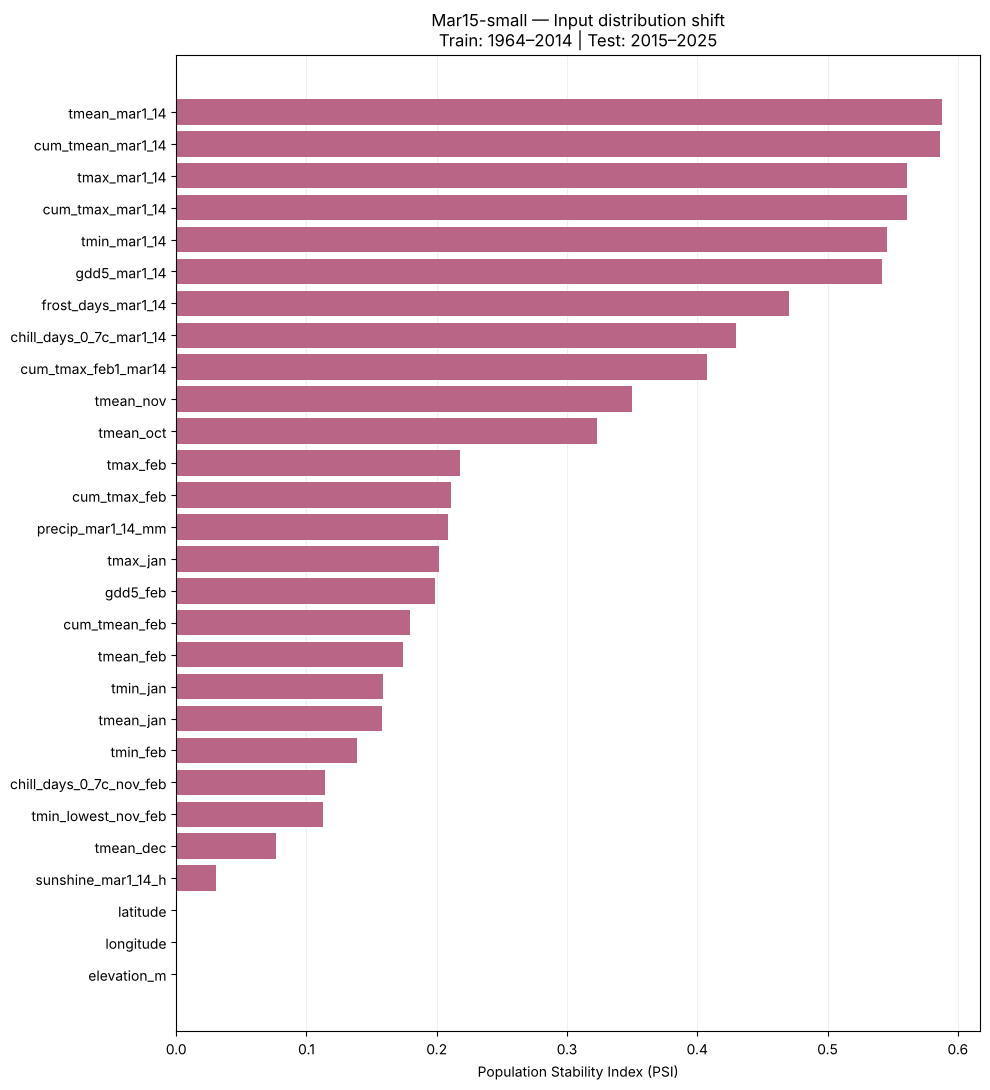

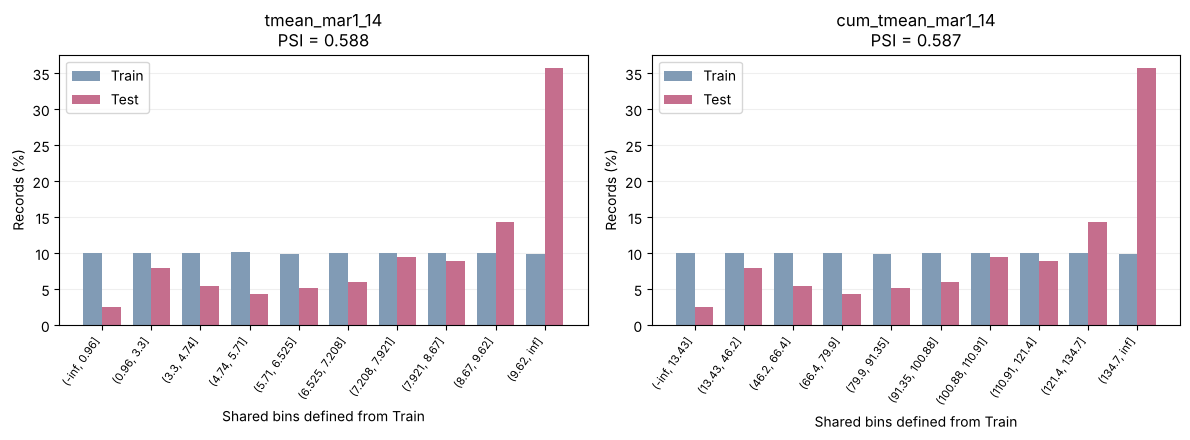

Saved to: /home/claude/sakura_analytics/results/monitoring


In [3]:
# ============================================================
# PSI of every feature
# ============================================================

fig, ax = plt.subplots(figsize=BAR_FIGSIZE)

ax.barh(
    drift_summary['feature'],
    drift_summary['PSI'],
    color='#B96586',
)

ax.invert_yaxis()
ax.set_xlabel('Population Stability Index (PSI)')
ax.set_title(
    'Mar15-small — Input distribution shift\n'
    'Train: 1964–2014 | Test: 2015–2025'
)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

for extension in ['png']:
    fig.savefig(
        MONITOR_OUT / f'feature_psi.{extension}',
        dpi=DPI,
        bbox_inches='tight',
    )

plt.show()


# ============================================================
# Distributions of the top features
# e.g. ['tmean_mar1_14', 'cum_tmax_mar1_14']
# ============================================================

FEATURES_TO_PLOT = drift_summary['feature'].head(2).tolist()

fig, axes = plt.subplots(
    1,
    len(FEATURES_TO_PLOT),
    figsize=DIST_FIGSIZE,
    squeeze=False,
)

for ax, feature in zip(axes.ravel(), FEATURES_TO_PLOT):
    bins = distribution_tables[feature]
    x = np.arange(len(bins))
    width = 0.38

    ax.bar(
        x - width / 2,
        bins['train_share'] * 100,
        width,
        label='Train',
        color='#819BB5',
    )
    ax.bar(
        x + width / 2,
        bins['test_share'] * 100,
        width,
        label='Test',
        color='#C56E8D',
    )

    psi = bins['PSI_contribution'].sum()

    ax.set_title(f'{feature}\nPSI = {psi:.3f}')
    ax.set_ylabel('Records (%)')
    ax.set_xlabel('Shared bins defined from Train')
    ax.set_xticks(x)
    ax.set_xticklabels(
        bins['bin'],
        rotation=55,
        ha='right',
        fontsize=8,
    )
    ax.legend()
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()

for extension in ['png']:
    fig.savefig(
        MONITOR_OUT / f'selected_feature_distributions.{extension}',
        dpi=DPI,
        bbox_inches='tight',
    )

plt.show()

print('Saved to:', MONITOR_OUT)

## 4. One-page figure for the slides: PSI (left) and distributions (right)

The report's Figure "Mean temperature, 1–14 March" is the `tmean_mar1_14` panel of this figure.

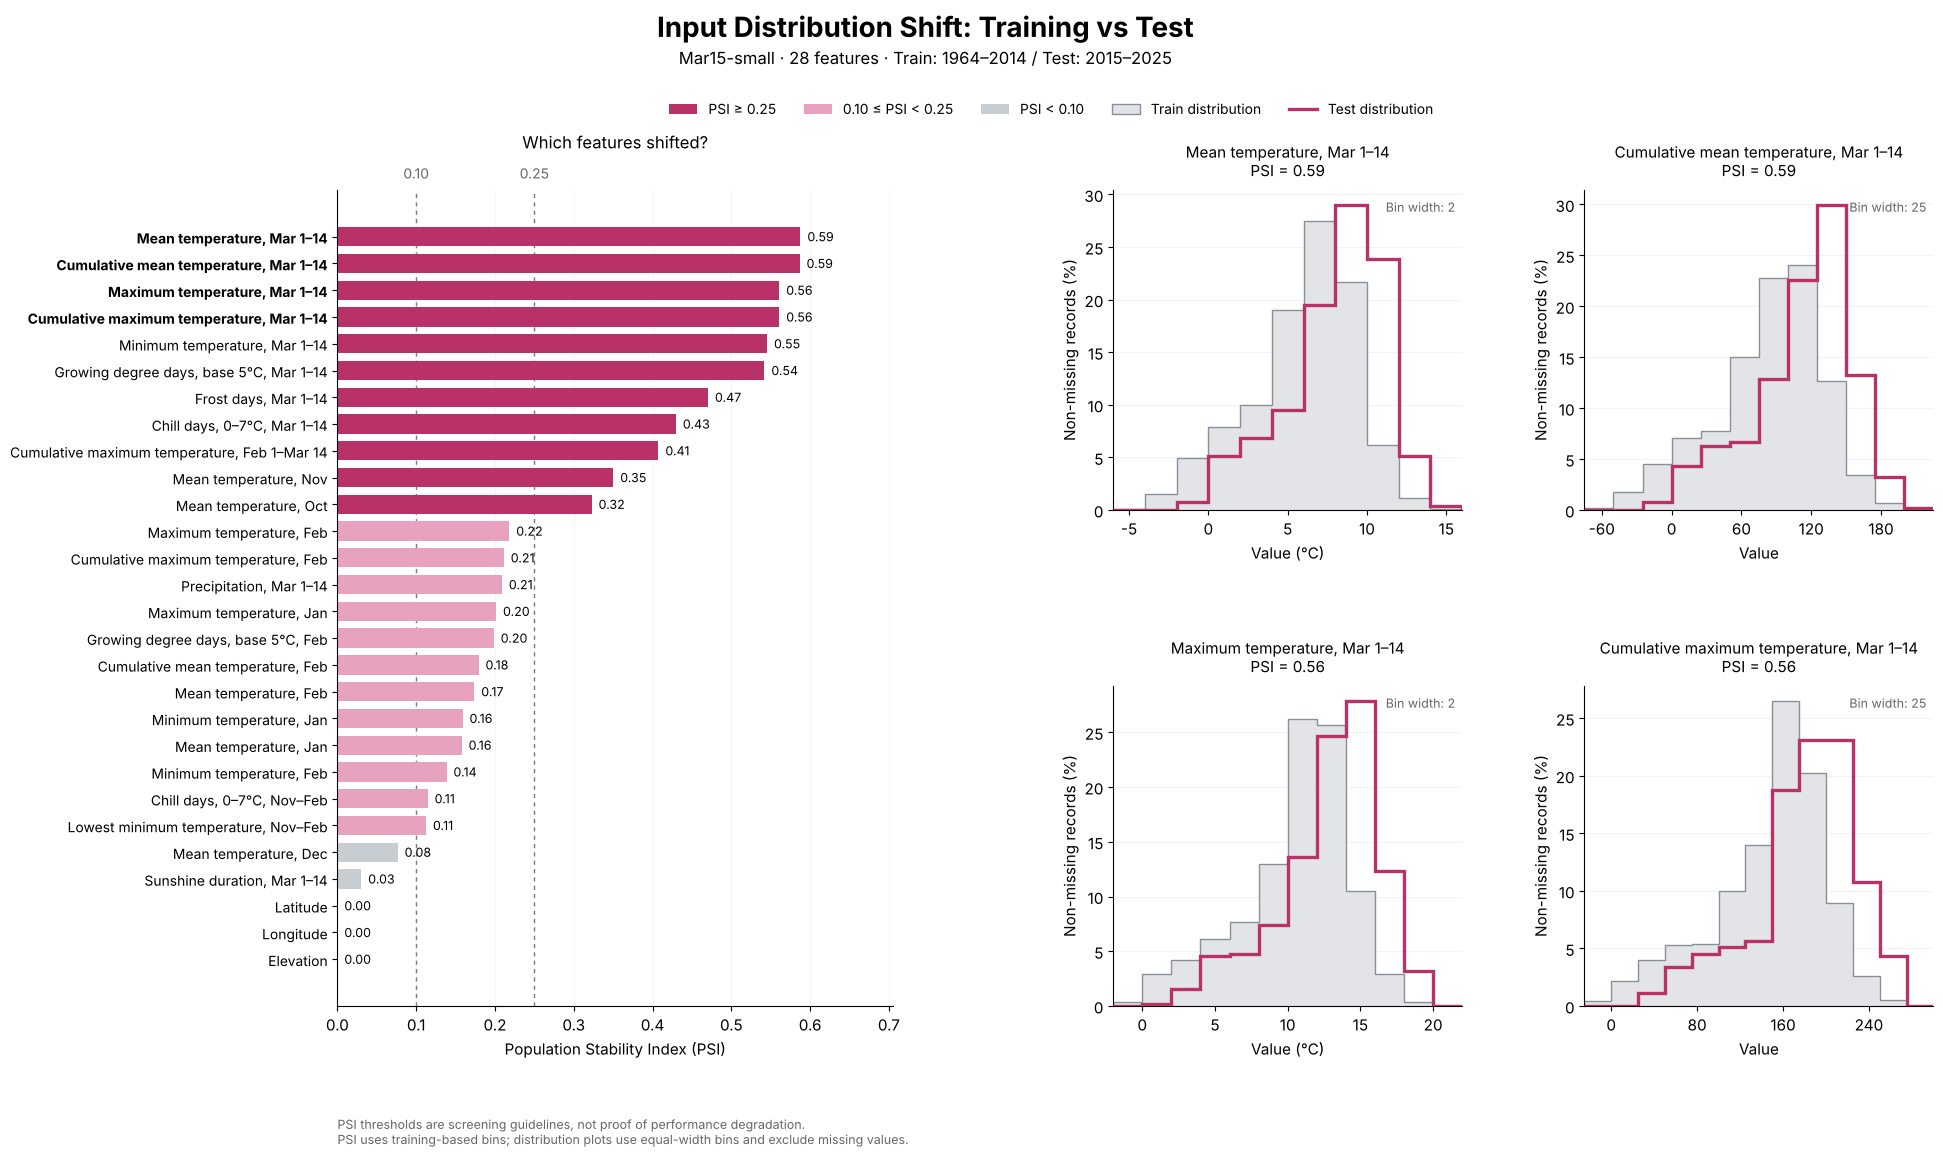

Saved to: /home/claude/sakura_analytics/results/monitoring


In [4]:
import re
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, FuncFormatter


# ============================================================
# 1. Display settings (change these)
# ============================================================

FIGSIZE = (21, 12)
FONT_SIZE = 11
DPI = 300

# Features shown on the right
# None = the top 4 by PSI.
# If those are near-duplicates, list 2-4 representative features instead.
SELECTED_FEATURES = None

# e.g.:
# SELECTED_FEATURES = [
#     'tmean_mar1_14',
#     'tmean_feb',
#     'sunshine_mar1_14_h',
#     'precip_mar1_14_mm',
# ]

# Bin width for the histograms (display only)
# Features not listed get a round width from the data range
BIN_WIDTHS = {
    'tmean_mar1_14': 2,
    'tmean_feb': 2,
    # 'cum_tmax_mar1_14': 50,
    # 'sunshine_mar1_14_h': 20,
}

# Add axis units only after checking the feature definition
UNIT_OVERRIDES = {
    # 'gdd5_mar1_14': '°C-days',
}

# Custom display names
NAME_OVERRIDES = {
    'latitude': 'Latitude',
    'longitude': 'Longitude',
    'elevation_m': 'Elevation',
}

COLORS = {
    'high': '#B83269',
    'moderate': '#E7A2BF',
    'low': '#C8CDD2',
    'train_fill': '#E1E3E6',
    'train_edge': '#898F96',
    'test': '#B83269',
}

# Optional one-line conclusion printed under the figure
TAKEAWAY = ''

SAVE_DIR = Path(MONITOR_OUT)
SAVE_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Readable feature names and units
# ============================================================

PERIODS = {
    'mar1_14': 'Mar 1–14',
    'feb1_mar14': 'Feb 1–Mar 14',
    'nov_feb': 'Nov–Feb',
    'nov_jan': 'Nov–Jan',
    'jan_feb': 'Jan–Feb',
    'oct': 'Oct',
    'nov': 'Nov',
    'dec': 'Dec',
    'jan': 'Jan',
    'feb': 'Feb',
}

PREFIXES = [
    ('chill_days_0_7c_', 'Chill days, 0–7°C'),
    ('tmin_lowest_', 'Lowest minimum temperature'),
    ('cum_tmean_', 'Cumulative mean temperature'),
    ('cum_tmax_', 'Cumulative maximum temperature'),
    ('frost_days_', 'Frost days'),
    ('tmean_', 'Mean temperature'),
    ('tmax_', 'Maximum temperature'),
    ('tmin_', 'Minimum temperature'),
    ('gdd5_', 'Growing degree days, base 5°C'),
    ('sunshine_', 'Sunshine duration'),
    ('precip_', 'Precipitation'),
]


def readable_name(feature):
    if feature in NAME_OVERRIDES:
        return NAME_OVERRIDES[feature]

    for prefix, description in PREFIXES:
        if feature.startswith(prefix):
            period = feature[len(prefix):]
            period = re.sub(r'_(mm|h)$', '', period)
            period = PERIODS.get(period, period.replace('_', ' '))
            return f'{description}, {period}'

    return feature.replace('_', ' ')


def feature_unit(feature):
    if feature in UNIT_OVERRIDES:
        return UNIT_OVERRIDES[feature]

    if feature in ('latitude', 'longitude'):
        return 'degrees'

    if feature == 'elevation_m':
        return 'm'

    if feature.startswith(('tmean_', 'tmax_', 'tmin_')):
        return '°C'

    if feature.startswith('precip_') and feature.endswith('_mm'):
        return 'mm'

    if feature.startswith('sunshine_') and feature.endswith('_h'):
        return 'hours'

    if feature.startswith(('chill_days_', 'frost_days_')):
        return 'days'

    # Do not guess units for cumulative features without checking the definition
    return ''


# ============================================================
# 3. Prepare the data
# ============================================================

ranked = (
    drift_summary.sort_values('PSI', ascending=False)
    .reset_index(drop=True)
)

if SELECTED_FEATURES is None:
    selected = ranked['feature'].head(4).tolist()
else:
    selected = list(SELECTED_FEATURES)

if len(selected) not in (2, 3, 4):
    raise ValueError('Choose 2-4 features for the distribution panels.')

if len(set(selected)) != len(selected):
    raise ValueError('SELECTED_FEATURES has duplicates.')

for feature in selected:
    if feature not in set(ranked['feature']):
        raise ValueError(f'Not in the PSI results: {feature}')

    if (
        feature not in train_monitor.columns
        or feature not in test_monitor.columns
    ):
        raise ValueError(f'Not in the data: {feature}')

psi_lookup = ranked.set_index('feature')['PSI'].to_dict()


# ============================================================
# 4. Round, equal-width bins for display
# (the PSI bins are not changed)
# ============================================================

def nice_bin_edges(train_values, test_values, feature):
    combined = np.concatenate([train_values, test_values])

    if len(combined) == 0:
        raise ValueError(f'{feature}: no values to show.')

    low = float(combined.min())
    high = float(combined.max())

    if feature in BIN_WIDTHS:
        width = float(BIN_WIDTHS[feature])

        if not np.isfinite(width) or width <= 0:
            raise ValueError(f'{feature}: invalid bin width.')

    else:
        # aim for roughly 10-15 bins
        target_width = (high - low) / 12

        if target_width <= 0:
            target_width = max(abs(low) * 0.1, 1.0)

        power = 10 ** np.floor(np.log10(target_width))
        choices = np.array([1, 2, 2.5, 5, 10]) * power
        width = float(choices[np.argmin(abs(choices - target_width))])

        if feature.startswith(('chill_days_', 'frost_days_')):
            width = max(1.0, float(np.ceil(width)))

    left = np.floor(low / width) * width
    right = np.ceil(high / width) * width

    if right <= left:
        left -= width / 2
        right = left + width

    n_bins = int(round((right - left) / width))

    if n_bins > 500:
        raise ValueError(
            f'{feature}: too many bins - increase BIN_WIDTHS.'
        )

    edges = left + np.arange(n_bins + 1) * width

    # make sure rounding does not drop the maximum
    if edges[-1] < high:
        edges = np.append(edges, edges[-1] + width)

    return edges, width


# ============================================================
# 5. One figure: PSI on the left, distributions on the right
# ============================================================

plt.rcParams.update({
    'font.size': FONT_SIZE,
    'axes.titlesize': FONT_SIZE + 1,
    'axes.labelsize': FONT_SIZE,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

fig = plt.figure(figsize=FIGSIZE)

layout = fig.add_gridspec(
    1, 2,
    width_ratios=[1.05, 1.55],
    left=0.22,
    right=0.98,
    bottom=0.15,
    top=0.83,
    wspace=0.32,
)

ax_psi = fig.add_subplot(layout[0, 0])

# ---------- left: PSI ----------
bar_colors = [
    COLORS['high'] if value >= 0.25
    else COLORS['moderate'] if value >= 0.10
    else COLORS['low']
    for value in ranked['PSI']
]

y = np.arange(len(ranked))

ax_psi.barh(
    y,
    ranked['PSI'],
    color=bar_colors,
    height=0.72,
)

ax_psi.set_yticks(y)
ax_psi.set_yticklabels(
    [readable_name(f) for f in ranked['feature']],
    fontsize=FONT_SIZE - 1,
)
ax_psi.invert_yaxis()

xmax = max(float(ranked['PSI'].max()), 0.25)
ax_psi.set_xlim(0, xmax * 1.20)

for threshold in [0.10, 0.25]:
    ax_psi.axvline(
        threshold,
        color='#777777',
        linestyle=(0, (3, 3)),
        linewidth=1,
        zorder=0,
    )
    ax_psi.text(
        threshold,
        1.01,
        f'{threshold:.2f}',
        transform=ax_psi.get_xaxis_transform(),
        ha='center',
        va='bottom',
        fontsize=FONT_SIZE - 1,
        color='#666666',
    )

for position, value in zip(y, ranked['PSI']):
    ax_psi.text(
        value + xmax * 0.015,
        position,
        f'{value:.2f}',
        va='center',
        fontsize=FONT_SIZE - 2,
    )

ax_psi.set_xlabel('Population Stability Index (PSI)')
ax_psi.set_title('Which features shifted?', pad=30)
ax_psi.grid(axis='x', alpha=0.12)
ax_psi.set_axisbelow(True)
ax_psi.spines['top'].set_visible(False)
ax_psi.spines['right'].set_visible(False)

# Bold the names of the features shown on the right
for tick, feature in zip(
    ax_psi.get_yticklabels(), ranked['feature']
):
    if feature in selected:
        tick.set_fontweight('bold')


# ---------- right: distributions ----------
if len(selected) == 2:
    right_grid = layout[0, 1].subgridspec(
        2, 1, hspace=0.50
    )
    positions = [(0, 0), (1, 0)]
else:
    right_grid = layout[0, 1].subgridspec(
        2, 2, hspace=0.55, wspace=0.35
    )
    positions = [(0, 0), (0, 1), (1, 0), (1, 1)]

for feature, position in zip(selected, positions):
    ax = fig.add_subplot(right_grid[position])

    train_values = (
        train_monitor[feature]
        .dropna()
        .to_numpy(dtype=float)
    )
    test_values = (
        test_monitor[feature]
        .dropna()
        .to_numpy(dtype=float)
    )

    if len(train_values) == 0 or len(test_values) == 0:
        ax.text(
            0.5, 0.5,
            'No non-missing observations in one period',
            transform=ax.transAxes,
            ha='center', va='center',
        )
        ax.set_title(readable_name(feature))
        continue

    edges, width = nice_bin_edges(
        train_values, test_values, feature
    )

    train_counts, _ = np.histogram(train_values, bins=edges)
    test_counts, _ = np.histogram(test_values, bins=edges)

    # The periods have different sizes, so compare shares
    train_pct = 100 * train_counts / len(train_values)
    test_pct = 100 * test_counts / len(test_values)

    ax.stairs(
        train_pct,
        edges,
        fill=True,
        color=COLORS['train_fill'],
        alpha=0.95,
        zorder=1,
    )

    ax.stairs(
        train_pct,
        edges,
        color=COLORS['train_edge'],
        linewidth=1,
        zorder=2,
    )

    ax.stairs(
        test_pct,
        edges,
        color=COLORS['test'],
        linewidth=2.4,
        zorder=3,
    )

    unit = feature_unit(feature)
    xlabel = f'Value ({unit})' if unit else 'Value'

    ax.set_xlabel(xlabel)
    ax.set_ylabel('Non-missing records (%)')
    ax.set_xlim(edges[0], edges[-1])
    ax.set_ylim(bottom=0)

    ax.set_title(
        f'{readable_name(feature)}\n'
        f'PSI = {psi_lookup[feature]:.2f}',
        fontsize=FONT_SIZE,
        pad=10,
    )

    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda value, _: f'{value:,.6g}')
    )

    ax.grid(axis='y', alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    ax.text(
        0.98, 0.97,
        f'Bin width: {width:g}',
        transform=ax.transAxes,
        ha='right', va='top',
        fontsize=FONT_SIZE - 2,
        color='#666666',
    )


# ============================================================
# 6. Title, legend and footnote
# ============================================================

fig.suptitle(
    'Input Distribution Shift: Training vs Test',
    fontsize=FONT_SIZE + 9,
    fontweight='bold',
    y=0.98,
)

fig.text(
    0.5, 0.935,
    f'Mar15-small · {len(ranked)} features · '
    'Train: 1964–2014 / Test: 2015–2025',
    ha='center',
    fontsize=FONT_SIZE + 1,
)

legend_handles = [
    Patch(
        facecolor=COLORS['high'],
        label='PSI ≥ 0.25',
    ),
    Patch(
        facecolor=COLORS['moderate'],
        label='0.10 ≤ PSI < 0.25',
    ),
    Patch(
        facecolor=COLORS['low'],
        label='PSI < 0.10',
    ),
    Patch(
        facecolor=COLORS['train_fill'],
        edgecolor=COLORS['train_edge'],
        label='Train distribution',
    ),
    Line2D(
        [], [],
        color=COLORS['test'],
        linewidth=2.4,
        label='Test distribution',
    ),
]

fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.56, 0.915),
    ncol=5,
    frameon=False,
    fontsize=FONT_SIZE - 1,
)

if TAKEAWAY:
    fig.text(
        0.22, 0.075,
        TAKEAWAY,
        fontsize=FONT_SIZE + 1,
        fontweight='bold',
        color='#70334D',
    )

fig.text(
    0.22, 0.035,
    'PSI thresholds are screening guidelines, not proof of performance degradation.\n'
    'PSI uses training-based bins; distribution plots use equal-width bins '
    'and exclude missing values.',
    fontsize=FONT_SIZE - 2,
    color='#666666',
)

for extension in ['png']:
    fig.savefig(
        SAVE_DIR / f'monitoring_overview.{extension}',
        dpi=DPI,
        bbox_inches='tight',
        facecolor='white',
    )

plt.show()

print('Saved to:', SAVE_DIR)